In [ ]:
import pandas as pd

df = pd.read_csv("/content/bank-full.csv", sep=";")
print(df.shape)
print(df["y"].value_counts(normalize=True))
df.head()

(45211, 17)
y
no     0.883015
yes    0.116985
Name: proportion, dtype: float64


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


In [ ]:
# 1. Tipos y nulos
df.info()

# 2. Resumen de números
print(df.describe())

# 3. Categorías: cuántos valores distintos
for col in df.select_dtypes(include="object").columns:
    print(f"\n{col}:")
    print(df[col].value_counts())

# 4. Conversión por poutcome (pista fuerte)
print(df.groupby("poutcome")["y"].apply(lambda s: (s == "yes").mean()))

# 5. pdays = -1 cuántos
print("\nNunca contactados (pdays=-1):", (df["pdays"] == -1).sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        45211 non-null  int64 
 1   job        45211 non-null  object
 2   marital    45211 non-null  object
 3   education  45211 non-null  object
 4   default    45211 non-null  object
 5   balance    45211 non-null  int64 
 6   housing    45211 non-null  object
 7   loan       45211 non-null  object
 8   contact    45211 non-null  object
 9   day        45211 non-null  int64 
 10  month      45211 non-null  object
 11  duration   45211 non-null  int64 
 12  campaign   45211 non-null  int64 
 13  pdays      45211 non-null  int64 
 14  previous   45211 non-null  int64 
 15  poutcome   45211 non-null  object
 16  y          45211 non-null  object
dtypes: int64(7), object(10)
memory usage: 5.9+ MB
                age        balance           day      duration      campaign  \
count  45211.000000

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split

d = df.copy()

# 1. Quitar duration
d = d.drop(columns=["duration"])

# 2. Objetivo a 0/1
d["y"] = (d["y"] == "yes").astype(int)

# 3. pdays = -1 -> bandera
d["nunca_contactado"] = (d["pdays"] == -1).astype(int)
d.loc[d["pdays"] == -1, "pdays"] = 0

# 4. Texto a números
X = pd.get_dummies(d.drop(columns="y"), drop_first=True)
y = d["y"]

# 5. Partir datos (mantener proporción 88/12)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Columnas:", X.shape[1])
print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Conversión train:", round(y_train.mean(), 4))
print("Conversión test:", round(y_test.mean(), 4))
print("duration en X:", "duration" in X.columns)

Columnas: 42
Train: (36168, 42) | Test: (9043, 42)
Conversión train: 0.117
Conversión test: 0.117
duration en X: False


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score, recall_score, precision_score, f1_score

modelos = {
    "logistica": make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=1000, class_weight="balanced"),
    ),
    "boosting": HistGradientBoostingClassifier(
        class_weight="balanced", random_state=42
    ),
}

probs = {}
for nombre, m in modelos.items():
    m.fit(X_train, y_train)
    p = m.predict_proba(X_test)[:, 1]
    probs[nombre] = p
    pred = (p >= 0.5).astype(int)
    print(f"\n{nombre}")
    print("  AUC-ROC :", round(roc_auc_score(y_test, p), 3))
    print("  Recall  :", round(recall_score(y_test, pred), 3))
    print("  Precisión:", round(precision_score(y_test, pred), 3))
    print("  F1      :", round(f1_score(y_test, pred), 3))


logistica
  AUC-ROC : 0.772
  Recall  : 0.623
  Precisión: 0.267
  F1      : 0.374

boosting
  AUC-ROC : 0.803
  Recall  : 0.638
  Precisión: 0.35
  F1      : 0.452


Conversión sin priorizar: 0.117
Top 10%: conversión 0.520 | mejora +344% | captura 44% de compradores
Top 20%: conversión 0.364 | mejora +212% | captura 62% de compradores
Top 30%: conversión 0.278 | mejora +138% | captura 71% de compradores
Control aleatorio 20%: 0.1169


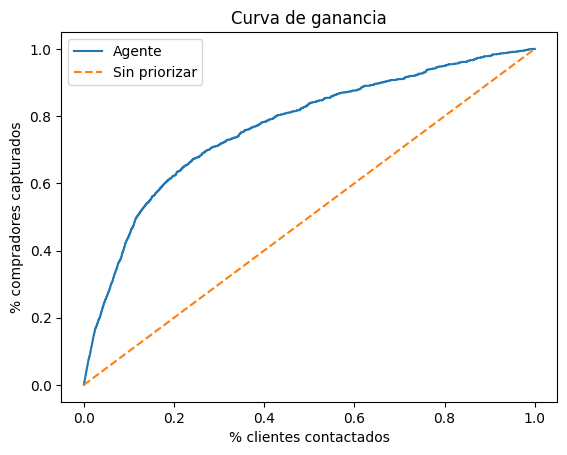

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

p = probs["boosting"]
res = pd.DataFrame({"p": p, "y": y_test.values})
res = res.sort_values("p", ascending=False).reset_index(drop=True)

base = res["y"].mean()
print("Conversión sin priorizar:", round(base, 4))

for frac in (0.10, 0.20, 0.30):
    n = int(len(res) * frac)
    top = res["y"].iloc[:n]
    conv = top.mean()
    cap = top.sum() / res["y"].sum()
    print(f"Top {int(frac*100)}%: conversión {conv:.3f} | "
          f"mejora {conv/base-1:+.0%} | captura {cap:.0%} de compradores")

# Control aleatorio: 1000 repeticiones con 20% de clientes
n = int(len(res) * 0.20)
rng = np.random.default_rng(42)
ctrl = [res["y"].sample(n, random_state=int(s)).mean()
        for s in rng.integers(0, 10**6, 1000)]
print("Control aleatorio 20%:", round(np.mean(ctrl), 4))

# Curva de ganancia
cum = res["y"].cumsum() / res["y"].sum()
x = np.arange(1, len(res) + 1) / len(res)
plt.plot(x, cum, label="Agente")
plt.plot([0, 1], [0, 1], "--", label="Sin priorizar")
plt.xlabel("% clientes contactados")
plt.ylabel("% compradores capturados")
plt.title("Curva de ganancia")
plt.legend()
plt.show()

In [ ]:
import numpy as np
import pandas as pd

class CampaignTargetAgent:
    def __init__(self, modelo, X_train, y_train, frac=0.20):
        self.modelo = modelo
        self.X = X_train.copy()
        self.y = y_train.copy()
        self.frac = frac
        self.historial = []

    def percibir(self, clientes):
        # Sensores: recibe clientes candidatos
        return clientes

    def decidir(self, clientes):
        # Razonamiento: probabilidad de compra y ranking
        r = clientes.copy()
        r["prob"] = self.modelo.predict_proba(clientes)[:, 1]
        r = r.sort_values("prob", ascending=False)
        n = int(len(r) * self.frac)
        return r.head(n)

    def actuar(self, lista, archivo):
        # Actuador: manda lista a plataforma (aquí, un CSV)
        lista[["prob"]].to_csv(archivo)
        return archivo

    def aprender(self, lista, y_real):
        # Aprendizaje: guarda resultado y reentrena
        resultado = y_real.loc[lista.index]
        self.historial.append({
            "campana": len(self.historial) + 1,
            "contactados": len(lista),
            "conversion": round(resultado.mean(), 4),
        })
        self.X = pd.concat([self.X, lista.drop(columns="prob")])
        self.y = pd.concat([self.y, resultado])
        self.modelo.fit(self.X, self.y)

# Simular dos campañas con dos mitades del test
agente = CampaignTargetAgent(modelos["boosting"], X_train, y_train, frac=0.20)
mitades = np.array_split(X_test.index, 2)

for i, idx in enumerate(mitades, 1):
    clientes = agente.percibir(X_test.loc[idx])
    lista = agente.decidir(clientes)
    agente.actuar(lista, f"campana_{i}.csv")
    agente.aprender(lista, y_test)

print(pd.DataFrame(agente.historial))
print("Base sin priorizar:", round(y_test.mean(), 4))

   campana  contactados  conversion
0        1          904      0.3650
1        2          904      0.3617
Base sin priorizar: 0.117


In [ ]:
import json
from datetime import datetime
import numpy as np
import pandas as pd
from sklearn.base import clone


class SimuladorBanco:
    """Ambiente simulado: manda clientes por tandas y devuelve respuestas."""
    def __init__(self, X, y, n_tandas=5, tasa_fallo=0.10, seed=42):
        self.rng = np.random.default_rng(seed)
        self.X, self.y = X, y
        self.tandas = np.array_split(self.rng.permutation(X.index), n_tandas)
        self.tasa_fallo = tasa_fallo

    def llegan_clientes(self, i):
        return self.X.loc[self.tandas[i]]

    def contactar(self, ids):
        ids = list(ids)
        ok = self.rng.random(len(ids)) > self.tasa_fallo  # estocástico
        alcanzados = [c for c, o in zip(ids, ok) if o]
        return self.y.loc[alcanzados]  # respuesta se revela DESPUÉS de actuar


class CampaignTargetAgent:
    """Agente que aprende: percibe -> decide -> actúa -> aprende."""
    def __init__(self, modelo, X_train, y_train, frac=0.20,
                 log_path="log_ejecucion.jsonl"):
        self.modelo = clone(modelo).fit(X_train, y_train)
        self.X, self.y = X_train.copy(), y_train.copy()
        self.frac = frac
        self.log_path = log_path
        open(self.log_path, "w").close()  # log limpio

    def _log(self, evento, ciclo, **datos):
        reg = {"timestamp": datetime.now().isoformat(timespec="milliseconds"),
               "ciclo": ciclo, "evento": evento, **datos}
        with open(self.log_path, "a") as f:
            f.write(json.dumps(reg) + "\n")

    def percibir(self, clientes, ciclo):
        self._log("percepcion", ciclo, n_clientes=int(len(clientes)))
        return clientes

    def decidir(self, clientes, ciclo):
        r = clientes.copy()
        r["prob"] = self.modelo.predict_proba(clientes)[:, 1]
        r = r.sort_values("prob", ascending=False)
        lista = r.head(int(len(r) * self.frac))
        self._log("decision", ciclo, n_elegidos=int(len(lista)),
                  prob_min=round(float(lista["prob"].min()), 4),
                  prob_media=round(float(lista["prob"].mean()), 4))
        return lista

    def actuar(self, lista, ciclo, ambiente):
        respuestas = ambiente.contactar(lista.index)
        self._log("accion", ciclo, n_enviados=int(len(lista)),
                  n_alcanzados=int(len(respuestas)))
        return respuestas

    def aprender(self, lista, respuestas, ciclo):
        nuevos = lista.loc[respuestas.index].drop(columns="prob")
        self.X = pd.concat([self.X, nuevos])
        self.y = pd.concat([self.y, respuestas])
        self.modelo.fit(self.X, self.y)
        self._log("aprendizaje", ciclo,
                  conversion=round(float(respuestas.mean()), 4),
                  n_entrenamiento=int(len(self.X)))


# --- Ejecución ---
sim = SimuladorBanco(X_test, y_test, n_tandas=5, tasa_fallo=0.10, seed=42)
agente = CampaignTargetAgent(modelos["boosting"], X_train, y_train, frac=0.20)

filas = []
for i in range(5):
    clientes = agente.percibir(sim.llegan_clientes(i), i + 1)
    lista = agente.decidir(clientes, i + 1)
    respuestas = agente.actuar(lista, i + 1, sim)
    agente.aprender(lista, respuestas, i + 1)
    base = y_test.loc[clientes.index].mean()   # solo para evaluar
    filas.append({"ciclo": i + 1, "base": round(base, 3),
                  "agente": round(respuestas.mean(), 3),
                  "mejora": f"{respuestas.mean()/base - 1:+.0%}"})

print(pd.DataFrame(filas))

   ciclo   base  agente mejora
0      1  0.124   0.401  +223%
1      2  0.114   0.358  +214%
2      3  0.116   0.357  +209%
3      4  0.121   0.391  +223%
4      5  0.110   0.324  +195%


In [ ]:
!head -n 8 log_ejecucion.jsonl
!wc -l log_ejecucion.jsonl

{"timestamp": "2026-10-18T21:58:25.710", "ciclo": 1, "evento": "percepcion", "n_clientes": 1809}
{"timestamp": "2026-10-18T21:58:25.742", "ciclo": 1, "evento": "decision", "n_elegidos": 361, "prob_min": 0.5152, "prob_media": 0.7331}
{"timestamp": "2026-10-18T21:58:25.744", "ciclo": 1, "evento": "accion", "n_enviados": 361, "n_alcanzados": 324}
{"timestamp": "2026-10-18T21:58:27.559", "ciclo": 1, "evento": "aprendizaje", "conversion": 0.4012, "n_entrenamiento": 36492}
{"timestamp": "2026-10-18T21:58:27.561", "ciclo": 2, "evento": "percepcion", "n_clientes": 1809}
{"timestamp": "2026-10-18T21:58:27.581", "ciclo": 2, "evento": "decision", "n_elegidos": 361, "prob_min": 0.5062, "prob_media": 0.725}
{"timestamp": "2026-10-18T21:58:27.582", "ciclo": 2, "evento": "accion", "n_enviados": 361, "n_alcanzados": 330}
{"timestamp": "2026-10-18T21:58:28.797", "ciclo": 2, "evento": "aprendizaje", "conversion": 0.3576, "n_entrenamiento": 36822}
20 log_ejecucion.jsonl


In [ ]:
import os
import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score

# Umbrales fijados ANTES de ejecutar las pruebas
UMBRAL = {"M1": 0.20, "M2": 0.75, "M3": 0.50, "M4": 0.10, "M5": 1.0}
REPS = 5
os.makedirs("logs_fase3", exist_ok=True)

def sin_columna(b): return b.drop(columns=["balance"])
def con_nan(b):     return b.assign(balance=np.nan)
def vacio(b):       return b.iloc[0:0]

ESC = [
 dict(id="N1", tipo="normal", frac=0.20, fallo=0.10, tandas=5),
 dict(id="N2", tipo="normal", frac=0.10, fallo=0.10, tandas=5),
 dict(id="N3", tipo="normal", frac=0.30, fallo=0.10, tandas=5),
 dict(id="N4", tipo="normal", frac=0.20, fallo=0.00, tandas=5),
 dict(id="L1", tipo="limite", frac=0.01, fallo=0.10, tandas=5),
 dict(id="L2", tipo="limite", frac=1.00, fallo=0.10, tandas=5),
 dict(id="L3", tipo="limite", frac=0.20, fallo=0.10, tandas=20),
 dict(id="L4", tipo="limite", frac=0.20, fallo=0.50, tandas=5),
 dict(id="F1", tipo="falla",  frac=0.20, fallo=0.90, tandas=5),
 dict(id="F2", tipo="falla",  frac=0.20, fallo=0.10, tandas=5, dano=sin_columna),
 dict(id="F3", tipo="falla",  frac=0.20, fallo=0.10, tandas=5, dano=con_nan),
 dict(id="F4", tipo="falla",  frac=0.20, fallo=0.10, tandas=5, dano=vacio),
]

def correr(e, seed):
    log = f"logs_fase3/{e['id']}_s{seed}.jsonl"
    sim = SimuladorBanco(X_test, y_test, e["tandas"], e["fallo"], seed)
    ag = CampaignTargetAgent(modelos["boosting"], X_train, y_train, e["frac"], log)
    base_y, resp_y, aucs, caps = [], [], [], []
    ok, err = 0, ""
    for i in range(e["tandas"]):
        try:
            lote = sim.llegan_clientes(i)
            if i == 1 and "dano" in e:          # daño en el segundo lote
                lote = e["dano"](lote)
            lote = ag.percibir(lote, i + 1)
            p = ag.modelo.predict_proba(lote)[:, 1]
            lista = ag.decidir(lote, i + 1)
            resp = ag.actuar(lista, i + 1, sim)
            ag.aprender(lista, resp, i + 1)
        except Exception as ex:
            err = type(ex).__name__
            continue
        yl = y_test.loc[lote.index]
        base_y.append(yl)
        resp_y.append(resp)
        caps.append(y_test.loc[lista.index].sum() / max(yl.sum(), 1))
        if yl.nunique() == 2:
            aucs.append(roc_auc_score(yl, p))
        ok += 1
    n_log = sum(1 for _ in open(log))
    base = pd.concat(base_y).mean() if base_y else np.nan
    r = pd.concat(resp_y) if resp_y else pd.Series(dtype=float)
    conv = r.mean() if len(r) else np.nan
    return dict(M1=conv / base - 1, M2=np.mean(aucs) if aucs else np.nan,
                M3=np.mean(caps) if caps else np.nan,
                M5=n_log / (4 * e["tandas"]), ok=ok, err=err)

filas = []
for e in ESC:
    d = pd.DataFrame([correr(e, s) for s in range(1, REPS + 1)])
    filas.append(dict(id=e["id"], tipo=e["tipo"],
                      ciclos_ok=f"{d.ok.mean():.1f}/{e['tandas']}",
                      M1=d.M1.mean(), M2=d.M2.mean(), M3=d.M3.mean(),
                      M4=d.M1.std(), M5=d.M5.mean(),
                      error=", ".join(sorted(set(x for x in d.err if x)))))
    print("listo", e["id"])

res = pd.DataFrame(filas)
res.to_csv("resultados_fase3.csv", index=False)
print(res.round(3).to_string(index=False))